In [32]:
'''
libs extenas
!pip install ruptures
'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import shapiro
from statsmodels.tsa.seasonal import STL
from classes.metrics.hurst import Hurst
ehc = pd.read_excel("database/Dados Demanda Ciclo Otto 8-3009.xlsx")
ehc['Unnamed: 0'] = pd.to_datetime(ehc['Unnamed: 0'])
ehc = ehc[['Unnamed: 0', 'Demanda Etanol Hidratado (m3)']].rename(columns={'Unnamed: 0': 'Data'})
ehc.set_index('Data', inplace=True)

## Diagnostico da serie 

### Hurst Coefficient: 

busca identificar se a serie possui comportamento persistente ou reversão a média

<Axes: >

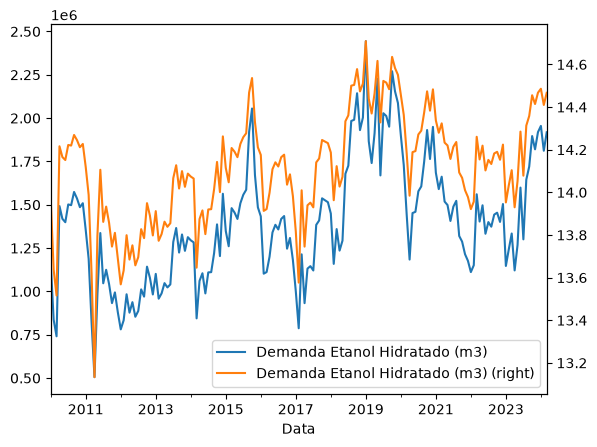

In [23]:
ax = ehc.plot()
np.log(ehc).plot(ax=ax, secondary_y=True)

Primeiro, encontramos o ciclo de sazonalidade

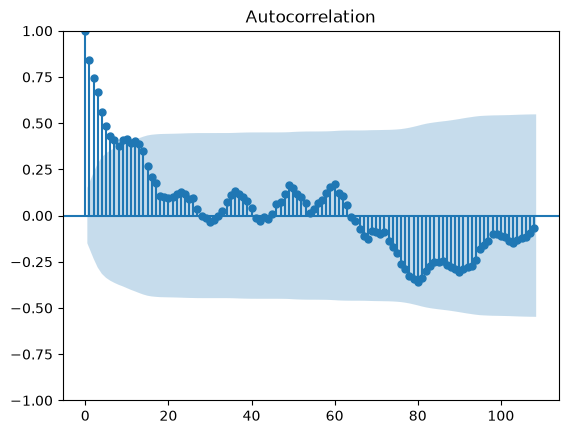

In [24]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(ehc['Demanda Etanol Hidratado (m3)'].dropna(), lags=108)
plt.show()

fazemos a decomposição da sazonalidade, para calcular o coeficiente.

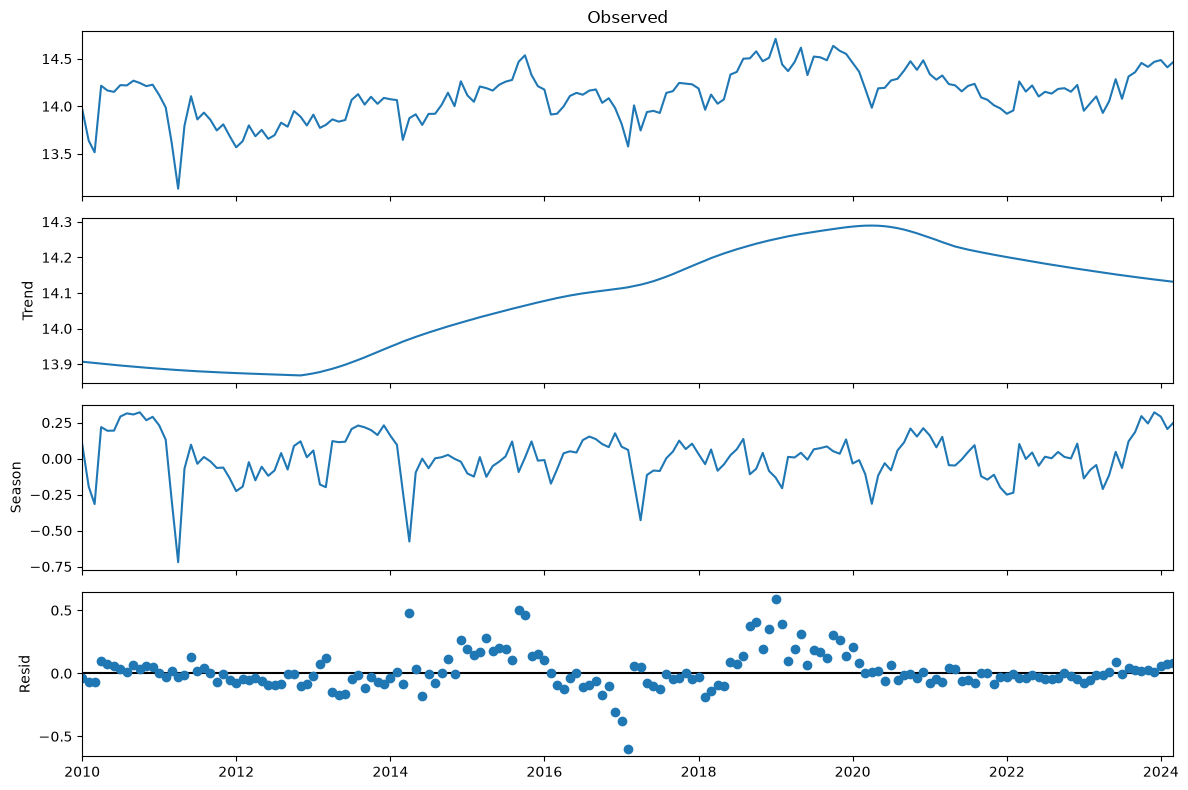

In [28]:
stl = STL(np.log(ehc), period=36, robust=True)
resultado = stl.fit()
fig = resultado.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

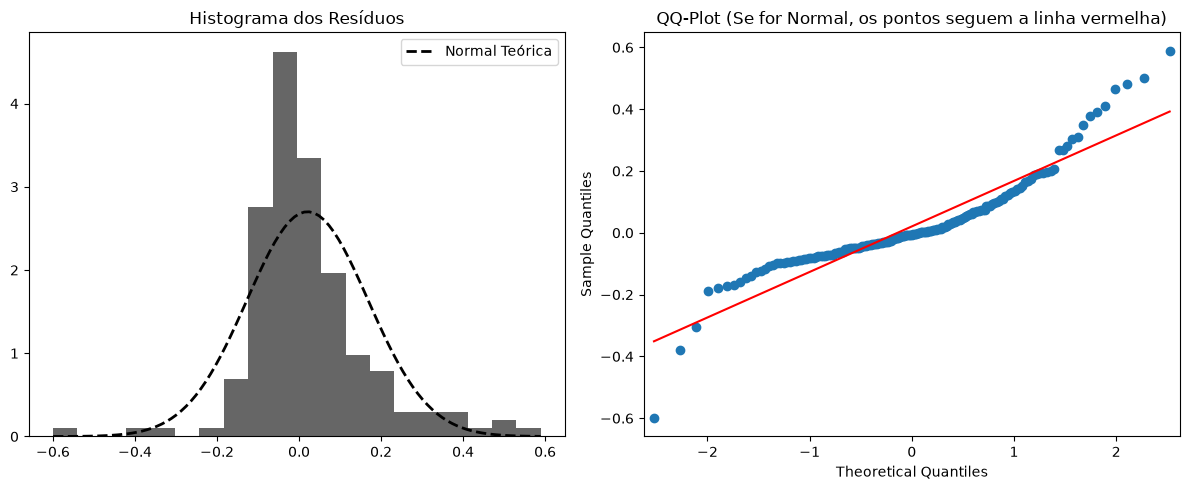

In [41]:
residuos = resultado.resid.dropna()

# Plotando a comparação com a Normal
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histograma com a curva da Normal sobreposta
ax[0].hist(residuos, bins=20, density=True, alpha=0.6, color='black')
x = np.linspace(residuos.min(), residuos.max(), 100)
ax[0].plot(x, stats.norm.pdf(x, residuos.mean(), residuos.std()), 'k--', lw=2, label='Normal Teórica')
ax[0].set_title('Histograma dos Resíduos')
ax[0].legend()

# 2. QQ-Plot (A forma mais precisa de validar normalidade)
sm.qqplot(residuos, line='s', ax=ax[1])
ax[1].set_title('QQ-Plot (Se for Normal, os pontos seguem a linha vermelha)')
plt.tight_layout()
plt.show()

### Encontrando o melhor periodo de sazonalidade

Fazemos uma iteração de [2,36] para identificar qual decomposição possui os residuos mais proximos a uma distribuição normal. Utilizamos um teste de normalidade formal, como o Teste de **Shapiro-Wilk**.

In [36]:
serie_log = np.log(ehc['Demanda Etanol Hidratado (m3)'].dropna())
melhor_periodo = None
melhor_stat = 0

for p in range(2, 37):
    try:
        stl = STL(serie_log, period=p, robust=True)
        resultado = stl.fit()
        residuos = resultado.resid.dropna()
        stat, p_valor = shapiro(residuos)
        
        # Atualiza se a distribuição atual for mais próxima da normal
        if stat > melhor_stat:
            melhor_stat = stat
            melhor_periodo = p
            
    except ValueError:
        # Pula caso o período seja maior que a quantidade de dados disponíveis
        continue

print(f"Melhor 'period' encontrado: {melhor_periodo}")
print(f"Estatística de Shapiro-Wilk (W): {melhor_stat:.4f} (mais próximo de 1 = mais normal)")

Melhor 'period' encontrado: 32
Estatística de Shapiro-Wilk (W): 0.9587 (mais próximo de 1 = mais normal)


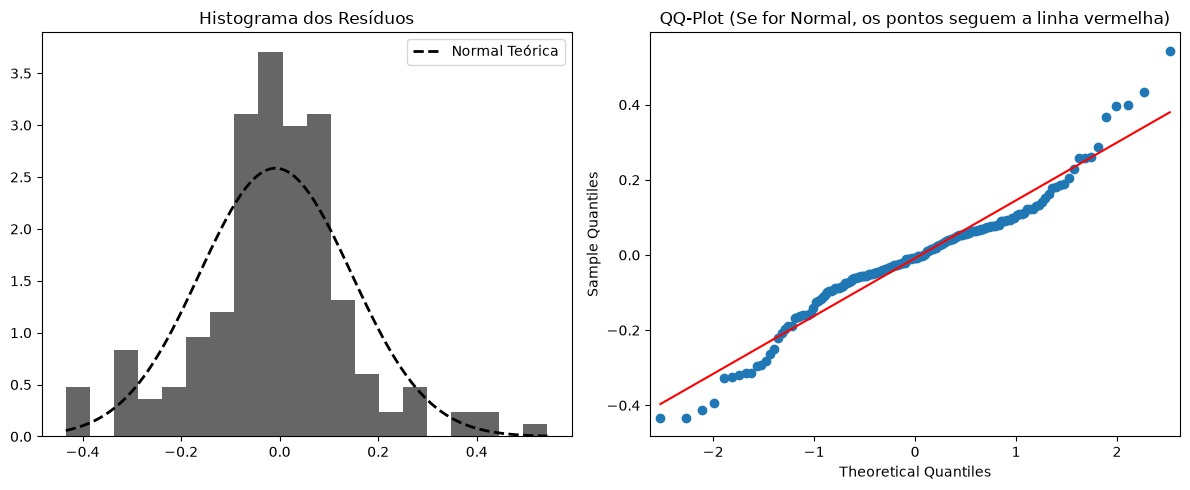

In [53]:
residuos = resultado.resid.dropna()

# Plotando a comparação com a Normal
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histograma com a curva da Normal sobreposta
ax[0].hist(residuos, bins=20, density=True, alpha=0.6, color='black')
x = np.linspace(residuos.min(), residuos.max(), 100)
ax[0].plot(x, stats.norm.pdf(x, residuos.mean(), residuos.std()), 'k--', lw=2, label='Normal Teórica')
ax[0].set_title('Histograma dos Resíduos')
ax[0].legend()

# 2. QQ-Plot (A forma mais precisa de validar normalidade)
sm.qqplot(residuos, line='s', ax=ax[1])
ax[1].set_title('QQ-Plot (Se for Normal, os pontos seguem a linha vermelha)')
plt.tight_layout()
plt.show()

In [42]:
stl = STL(np.log(ehc), period=32, robust=True)
resultado = stl.fit()

In [43]:
serie_dessazonalizada = np.log(ehc)['Demanda Etanol Hidratado (m3)'] - resultado.seasonal

In [44]:
hurst = Hurst(q=2, min_t=3, max_t=13)
valor_h, regime = hurst.calculate(serie_dessazonalizada)
print(f"Hurst sem sazonalidade: {valor_h:.4f} | Regime: {regime}")

Hurst sem sazonalidade: 0.1932 | Regime: Anti-persistente


## Deslocamento na média 01: Algoritmo PELT

Já identificamos que a serie possui um forte comportamento anti-persistente. Agora buscaremos saber se houve deslocamento na média.

Índices onde houve deslocamento de média: [55]


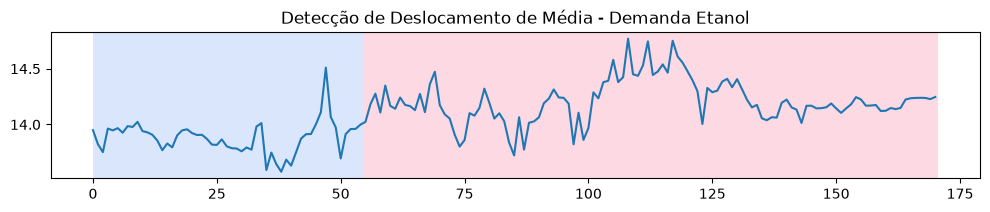

In [45]:
import ruptures as rpt

sinal = serie_dessazonalizada.values if hasattr(serie_dessazonalizada, 'values') else serie_dessazonalizada

# Detecta mudanças de média (modelo 'l2' busca quebras na média)
algo = rpt.Pelt(model="l2").fit(sinal)
pontos_quebra = algo.predict(pen=3) # 'pen' controla a sensibilidade (quanto maior, menos quebras detecta)

print("Índices onde houve deslocamento de média:", pontos_quebra[:-1])

# Plota a série com as quebras detectadas
rpt.display(sinal, pontos_quebra)
plt.title("Detecção de Deslocamento de Média - Demanda Etanol")
plt.show()

## Deslocamento na média 02: Regressão na média de cada ano

Regressão linear ajustada sobre as médias anuais (linha verde tracejada mostrando a direção geral de longo prazo)

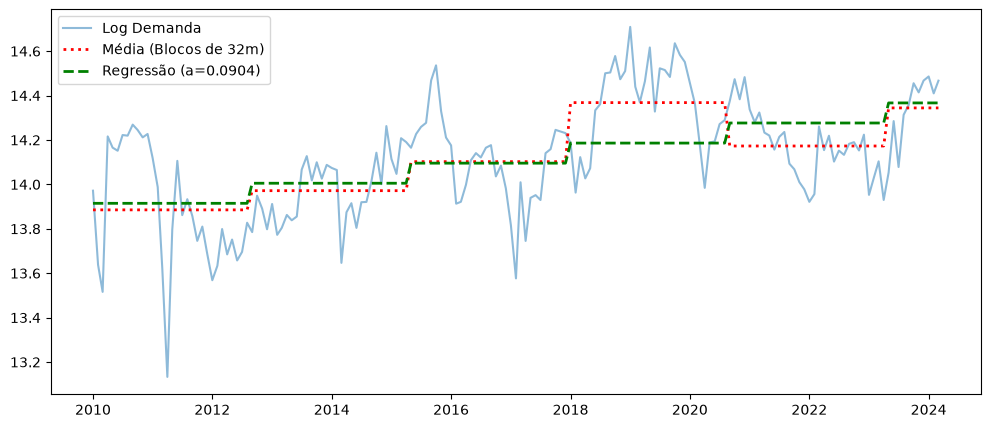

In [52]:
ehc['log_demanda'] = np.log(ehc['Demanda Etanol Hidratado (m3)'])

ehc['ciclo_32m'] = np.arange(len(ehc)) // 32
ehc['media_ciclo'] = ehc.groupby('ciclo_32m')['log_demanda'].transform('mean')

medias = ehc.groupby('ciclo_32m')['log_demanda'].mean()
a, b = np.polyfit(medias.index, medias.values, 1)
ehc['regressao'] = a * ehc['ciclo_32m'] + b

plt.figure(figsize=(12, 5))
plt.plot(ehc.index, ehc['log_demanda'], label='Log Demanda', alpha=0.5)
plt.plot(ehc.index, ehc['media_ciclo'], 'r:', linewidth=2, label='Média (Blocos de 32m)')
plt.plot(ehc.index, ehc['regressao'], 'g--', linewidth=2, label=f'Regressão (a={a:.4f})')
plt.legend()
plt.show()

## Conclusão: 

**Série Anti-Persistente / demanda de etanol com H = 0,2**

• O que a rede precisa fazer: **Capturar oscilações curto prazo** e reversão à média  

• Arquiteturas indicadas: Modelos focados em padrões locais como N-BEATS, N-HiTS ou redes lineares modernas como DLinear / PatchTST. Evvitar LSTMs, profundas costumam sofrer overfitting (decoram o ruído) nesse cenário.  

• Tamanho da janela (Lookback): Curtas (ex: 6 a x passos). Como a série reverte rápido, olhar muito para trás só adiciona ruído ao treinamento.  

• Pré-processamento crítico: Para reversão na média usar **RevIN** 